# Market Data and Candlesticks

## Stock Forecasting Project

**Target stock:** Coca-Cola (KO)
**Data source:** Yahoo Finance
**Data download date:** 22 November 2026
**Historical period:** 2 January 2015 – 9 November 2026
**Number of trading observations:** 2,981

### Objective
This notebook explores the historical market data for Coca-Cola (KO), checks data quality, visualises price movements using candlestick charts, and examines daily returns as preparation for time-series forecasting.

## Stock Selection and Justification

The selected target stock for this forecasting project is **The Coca-Cola Company (KO)**.

Coca-Cola was selected for the following reasons:

1. **Historical data availability:** Coca-Cola has extensive historical stock-market data, making it suitable for time-series analysis.
2. **Established company:** It is a well-known publicly traded company with a long trading history.
3. **Forecasting suitability:** Its historical prices and returns provide an opportunity to investigate trends, stationarity, autocorrelation and volatility.
4. **Project requirements:** KO is not among the excluded example stocks specified for this project.

Coca-Cola therefore provides a suitable dataset for investigating financial time-series forecasting methods.

## Data Configuration

The project configuration was set up in `tslab/config.py`.

- **TARGET_TICKER:** Set to `"KO"` to identify Coca-Cola as the target stock.
- **INITIAL_TRAIN:** Set to `1000`, representing the initial training-window size used by the project's forecasting configuration.

The target ticker was changed from the original `"GOOGL"` to `"KO"` to match our selected stock.

The initial training size was retained at its original value of `1000`.

These settings ensure that the project uses Coca-Cola as its target stock while maintaining the existing training configuration.

In [1]:
import pandas as pd
from pathlib import Path

# Load Coca-Cola stock data
data_path = Path("../data/target_KO.csv")
df = pd.read_csv(data_path, index_col=0, parse_dates=True)

# Display the first five rows
df.head()

,Open,High,Low,Close,Volume
Date,,,,,
2015-01-02,29.299123,29.396188,28.980203,29.215927,9921100
2015-01-05,29.597245,29.791373,29.174330,29.215927,26292600
2015-01-06,29.403123,29.770575,29.285262,29.437788,16897500
2015-01-07,29.673505,29.888431,29.520979,29.805235,13412300
2015-01-08,29.936976,30.207365,29.881510,30.165766,21743600


In [2]:
# Check the size of the dataset
print("Dataset shape:", df.shape)

# Check column names
print("\nColumns:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Check the date range
print("\nFirst date:", df.index.min())
print("Last date:", df.index.max())

Dataset shape: (2981, 5)

Columns:
['Open', 'High', 'Low', 'Close', 'Volume']

Data types:
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

First date: 2015-01-02 00:00:00
Last date: 2026-11-09 00:00:00


## 1. Dataset Overview

The dataset contains historical daily trading data for Coca-Cola (KO), obtained from Yahoo Finance.

The dataset covers the period from **2 January 2015 to 9 November 2026**, with a total of **2,981 trading observations**.

It contains five variables:

| Variable | Description |
|---|---|
| Open | Price at the beginning of the trading session |
| High | Highest price during the trading session |
| Low | Lowest price during the trading session |
| Close | Price at the end of the trading session |
| Volume | Number of shares traded |

All price variables are stored as floating-point numbers, while Volume is stored as an integer.

These variables provide the information needed to examine historical price movements, trading activity and daily returns.

In [3]:
# Basic data quality checks

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate dates:", df.index.duplicated().sum())

print("\nRepeated closing prices:", df["Close"].duplicated().sum())

print("\nNon-positive closing prices:", (df["Close"] <= 0).sum())

print("\nDays where High is below Low:", (df["High"] < df["Low"]).sum())

print("\nZero-volume days:", (df["Volume"] == 0).sum())

Missing values:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Duplicate dates: 0

Repeated closing prices: 232

Non-positive closing prices: 0

Days where High is below Low: 0

Zero-volume days: 0


## 2. Data Quality Assessment

The dataset was checked for missing values, duplicate dates, repeated closing prices, non-positive prices, inconsistent high and low values, and zero trading volume.

### Data Quality Results

| Check | Result |
|---|---:|
| Missing values | 0 |
| Duplicate dates | 0 |
| Repeated closing prices | 232 |
| Non-positive closing prices | 0 |
| Days where High is below Low | 0 |
| Zero-volume days | 0 |

### Interpretation

The dataset is generally clean and suitable for further analysis.

- **Missing values:** No missing observations were found in any of the five variables.
- **Duplicate dates:** There are no duplicate trading dates, indicating that each date appears only once.
- **Repeated closing prices:** There are 232 repeated closing-price values. This does not necessarily indicate an error, as a stock can close at the same price on different trading days.
- **Non-positive prices:** No zero or negative closing prices were found.
- **High and Low consistency:** There are no observations where the daily high is below the daily low.
- **Trading volume:** There are no days with zero trading volume.

Overall, the checks indicate that the dataset has good basic data quality. The repeated closing prices should be treated as normal market observations unless further investigation suggests otherwise.

In [4]:
# Check gaps between consecutive trading dates

date_gaps = df.index.to_series().diff().dt.days

print("Longest gap between observations:", date_gaps.max(), "calendar days")

print("\nLargest date gaps:")
print(date_gaps.sort_values(ascending=False).head(10))

Longest gap between observations: 4.0 calendar days

Largest date gaps:
Date
2026-06-22    4.0
2015-02-17    4.0
2018-02-20    4.0
2018-01-16    4.0
2018-01-02    4.0
2017-05-30    4.0
2015-04-06    4.0
2015-01-20    4.0
2017-12-26    4.0
2018-04-02    4.0
Name: Date, dtype: float64


### Trading Date Gaps

The time differences between consecutive observations were examined to identify unusually long gaps in the historical data.

The longest gap between consecutive trading observations was **4 calendar days**.

This is consistent with normal stock-market closures, including weekends and public holidays. Therefore, these gaps do not automatically indicate missing trading observations.

No unusually long gaps were identified from this check.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


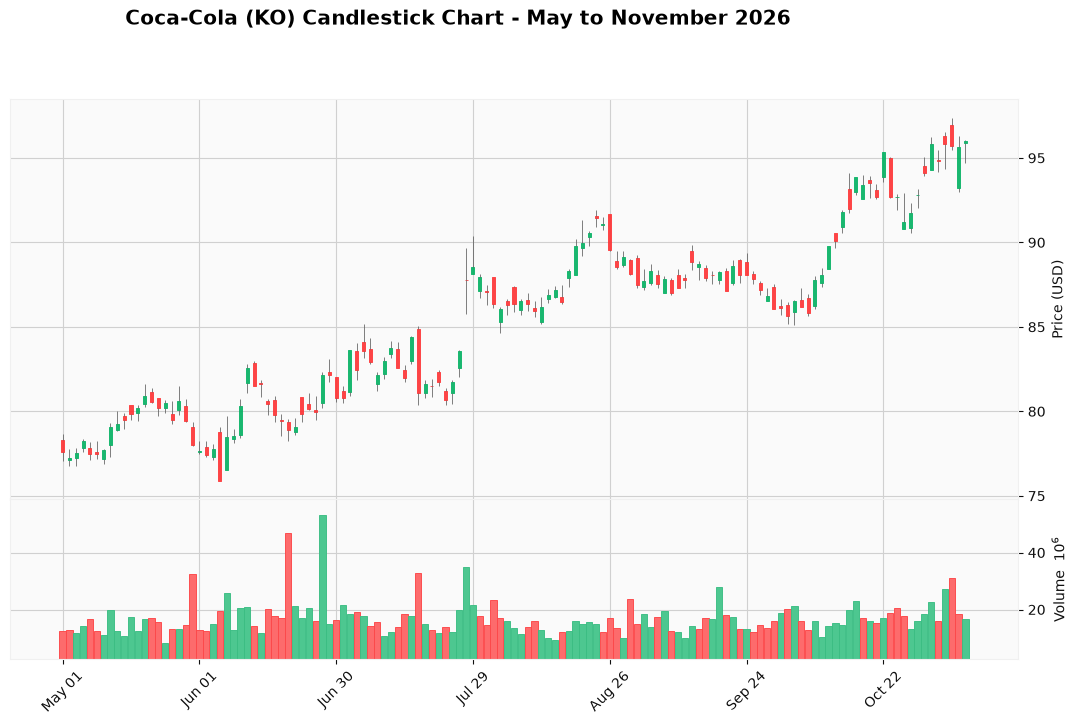

In [5]:
import mplfinance as mpf

# Select the most recent 6 months of trading data
recent_data = df.loc["2026-05-01":"2026-11-09"]

# Create candlestick chart
mpf.plot(
    recent_data,
    type="candle",
    style="yahoo",
    title="Coca-Cola (KO) Candlestick Chart - May to November 2026",
    ylabel="Price (USD)",
    volume=True,
    figsize=(14, 8)
)

In [8]:
# Check for missing weekdays in the date range
all_weekdays = pd.bdate_range(
    start=df.index.min(),
    end=df.index.max()
)

missing_weekdays = all_weekdays.difference(df.index)

print("Number of weekdays missing from the dataset:", len(missing_weekdays))
print("First missing dates:")
print(missing_weekdays[:20])

Number of weekdays missing from the dataset: 111
First missing dates:
DatetimeIndex(['2015-01-19', '2015-02-16', '2015-04-03', '2015-05-25',
               '2015-07-03', '2015-09-07', '2015-11-26', '2015-12-25',
               '2016-01-01', '2016-01-18', '2016-02-15', '2016-03-25',
               '2016-05-30', '2016-07-04', '2016-09-05', '2016-11-24',
               '2016-12-26', '2017-01-02', '2017-01-16', '2017-02-20'],
              dtype='datetime64[us]', freq=None)


### Missing Trading Days Analysis

The dataset contains 111 weekdays without observations between 2 January 2015 and 9 November 2026.

However, these dates should not automatically be classified as missing trading days. Several dates correspond to official US stock market holidays, including Martin Luther King Jr. Day, Presidents' Day, Good Friday and Memorial Day.

The absence of observations on these dates is therefore expected because the US stock market was closed.

**Conclusion:** The 111 missing weekdays do not necessarily indicate a data collection problem. They include scheduled market closures. The dataset contains 2,981 trading-day observations, with no duplicate dates or missing values in the downloaded records.

## 3. Candlestick Chart Analysis

A candlestick chart was created to visualise Coca-Cola's daily stock price movements from May to November 2026.

Each candlestick represents one trading session:

- The **body** represents the difference between the opening and closing prices.
- The **upper shadow** represents the highest price reached during the session.
- The **lower shadow** represents the lowest price reached during the session.
- The volume bars show the number of shares traded.

Green and red candles help distinguish between sessions where the closing price was above or below the opening price.

The chart provides a visual overview of daily price fluctuations, trading activity and short-term market behaviour. It also helps identify periods of relatively large price movements and changes in trading volume.

In [6]:
import numpy as np

# Calculate daily log returns
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# Display the first observations
print(df[["Close", "Log_Return"]].head(10))

# Summary statistics
print("\nLog return summary:")
print(df["Log_Return"].describe())

                Close  Log_Return
Date                             
2015-01-02  29.215927         NaN
2015-01-05  29.215927    0.000000
2015-01-06  29.437788    0.007565
2015-01-07  29.805235    0.012405
2015-01-08  30.165766    0.012024
2015-01-09  29.832968   -0.011094
2015-01-12  29.562588   -0.009104
2015-01-13  29.555651   -0.000235
2015-01-14  29.507114   -0.001644
2015-01-15  29.382330   -0.004238

Log return summary:
count    2980.000000
mean        0.000399
std         0.011315
min        -0.101728
25%        -0.004813
50%         0.000480
75%         0.005963
max         0.062783
Name: Log_Return, dtype: float64


## 4. Daily Log Returns

Daily log returns were calculated using the closing prices of Coca-Cola (KO).

The calculation used was:

\[
r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)
\]

where \(P_t\) represents the current day's closing price and \(P_{t-1}\) represents the previous trading day's closing price.

### Summary Statistics

| Statistic | Value |
|---|---:|
| Number of returns | 2,980 |
| Mean | 0.000399 |
| Standard deviation | 0.011315 |
| Minimum | -0.101728 |
| Median | 0.000480 |
| Maximum | 0.062783 |

The mean daily log return is approximately 0.0399%, while the standard deviation is approximately 1.13%.

The minimum and maximum returns indicate that daily price movements can vary considerably. The first return is missing because there is no previous observation

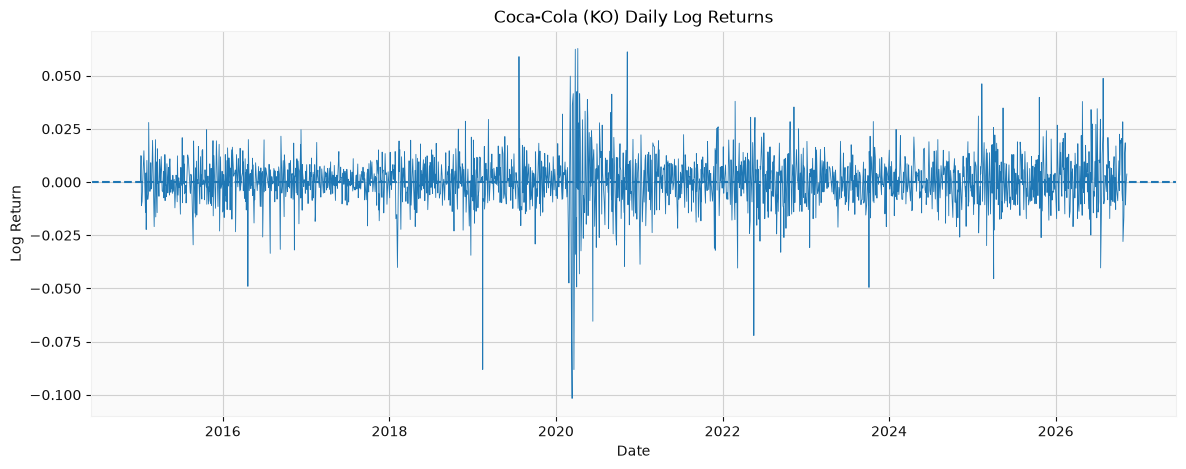

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(df.index, df["Log_Return"], linewidth=0.6)

plt.axhline(0, linestyle="--")

plt.title("Coca-Cola (KO) Daily Log Returns")
plt.xlabel("Date")
plt.ylabel("Log Return")

plt.show()

### Daily Log Returns Visualisation

The daily log returns fluctuate around zero, with both positive and negative movements.

Most daily movements appear relatively small, while some observations show larger positive or negative changes. These larger movements represent periods of greater daily price variation.

The graph provides an initial indication that stock returns are not constant over time. Further investigation of stationarity, autocorrelation and volatility will be carried out in the next notebook.